# Multi-Label Weather Phenomena Classification Experiment using Transfer Learning

## Overview
This notebook implements an **experimental multi-label classification** approach using **transfer learning** with **EfficientNetB0** (pre-trained on ImageNet).

**Important Note**: This is an **experimental setup** to test whether the model can learn multi-label patterns despite the dataset being inherently multi-class.

## Model Architecture
- **Base Model**: EfficientNetB0 (transfer learning from ImageNet weights)
- **Output Layer**: **Sigmoid activation** for multi-label classification (instead of softmax)
- **Loss Function**: **Binary crossentropy** (instead of categorical crossentropy)
- **Training Strategy**: Two-phase training (frozen base + fine-tuning)

## Dataset Structure
**Note**: The dataset is the **same as the multi-class version** — each image belongs to exactly one weather category:
- dew
- fogsmog
- frost
- glaze
- hail
- lightning
- rain
- rainbow
- rime
- sandstorm
- snow
- volcanos (self-created class)

## Experiment Goal
Although the dataset contains **only single-label data** (multi-class), we're using **sigmoid activation and binary crossentropy** to explore:
1. Can the model learn to classify correctly despite the loss function mismatch?
2. How does multi-label architecture perform on single-label data?
3. What patterns emerge when treating multi-class data as multi-label?

This experimental approach helps understand the flexibility and limitations of different output configurations.

## Library Installation

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.applications.efficientnet import preprocess_input

# Configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✓ GPU memory growth enabled for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(f"GPU configuration error: {e}")

import matplotlib.pyplot as plt
import seaborn as sns
import gc 
import random
import numpy as np
import os
import shutil
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.spatial.distance import cdist

sns.set_style('whitegrid')
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

✓ GPU memory growth enabled for 1 GPU(s)
TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Path Configuration

In [7]:
# Proyect Path
MAIN_PATH = './Part-1'
# Base path of your dataset
BASE_PATH = MAIN_PATH + '/dataset'

if os.path.exists(BASE_PATH):
    print(f"✓ Path found: {BASE_PATH}")
    print(f"Available folders: {os.listdir(BASE_PATH)}")
else:
    print(f"✗ Path not found. Please adjust BASE_PATH")

✓ Path found: ./Part-1/dataset
Available folders: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow', 'volcanos']


## Hyperparameter Configuration

In [8]:
CONFIG = {
    'IMG_SIZE': (224, 224),
    'BATCH_SIZE': 16,
    'EPOCHS': 20,
    'LEARNING_RATE': 0.001,
    'VALIDATION_SPLIT': 0.2,
    'SEED': 42
}

np.random.seed(CONFIG['SEED'])
tf.random.set_seed(CONFIG['SEED'])

print("Model configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Model configuration:
  IMG_SIZE: (224, 224)
  BATCH_SIZE: 16
  EPOCHS: 20
  LEARNING_RATE: 0.001
  VALIDATION_SPLIT: 0.2
  SEED: 42


## Dataset Preparation and Exploration

✓ Balanced dataset already exists: ./Part-1/dataset_balanced


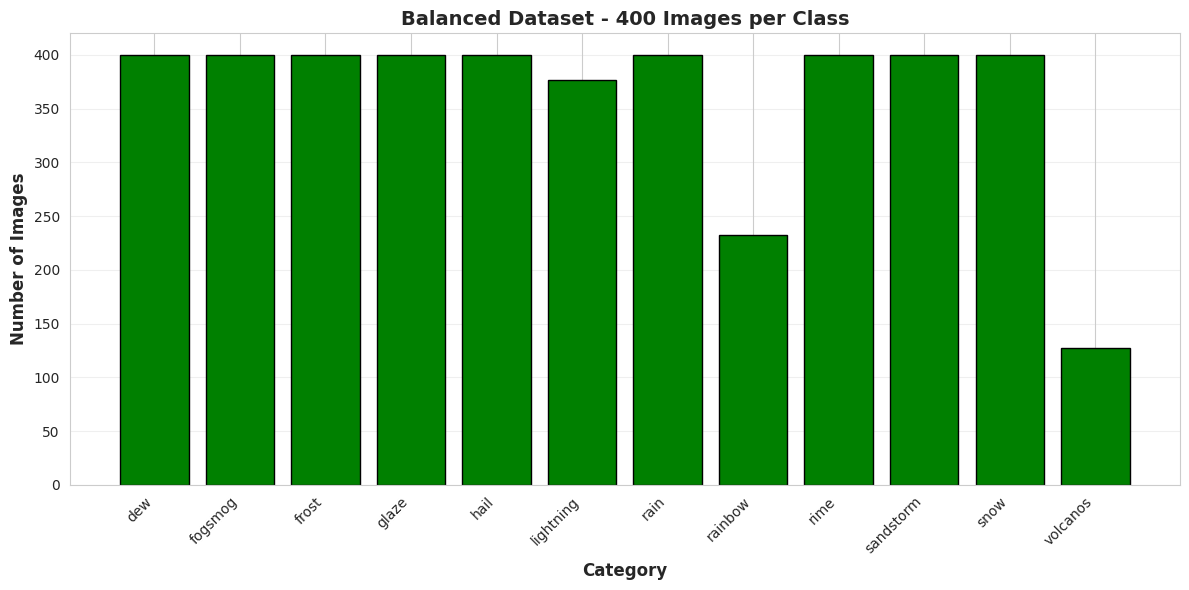

Found 3470 images belonging to 12 classes.
Found 866 images belonging to 12 classes.


In [9]:
def create_balanced_dataset(base_path, max_samples_per_class=100):
    """
    Creates a balanced dataset by copying max X images per category
    """

    balanced_path = base_path + "_balanced"

    if os.path.exists(balanced_path):
        print(f"✓ Balanced dataset already exists: {balanced_path}")
        return balanced_path

    os.makedirs(balanced_path)

    categories = [d for d in os.listdir(base_path)
                 if os.path.isdir(os.path.join(base_path, d))]

    for category in categories:
        category_path = os.path.join(base_path, category)
        balanced_category_path = os.path.join(balanced_path, category)
        os.makedirs(balanced_category_path, exist_ok=True)

        images = [f for f in os.listdir(category_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        if len(images) > max_samples_per_class:
            selected_images = np.random.choice(images, max_samples_per_class, replace=False)
        else:
            selected_images = images

        for img in selected_images:
            src = os.path.join(category_path, img)
            dst = os.path.join(balanced_category_path, img)
            shutil.copy2(src, dst)

        print(f"✓ {category}: {len(selected_images)} images")

    print(f"\nBalanced dataset created at: {balanced_path}")
    return balanced_path

BALANCED_PATH = create_balanced_dataset(BASE_PATH, max_samples_per_class=400)
BASE_PATH = BALANCED_PATH

def explore_dataset_balanced(base_path):
    """Explores the balanced dataset"""

    categories = [d for d in os.listdir(base_path)
                  if os.path.isdir(os.path.join(base_path, d))]

    data = []
    total_images = 0

    for category in sorted(categories):
        category_path = os.path.join(base_path, category)
        images = [f for f in os.listdir(category_path)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        num_images = len(images)
        total_images += num_images

        data.append({
            'Category': category,
            'Number of images': num_images
        })

    df = pd.DataFrame(data)

    plt.figure(figsize=(12, 6))
    plt.bar(df['Category'], df['Number of images'], color='green', edgecolor='black')
    plt.xlabel('Category', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Balanced Dataset - 400 Images per Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return df, categories

df_distribution, CATEGORIES = explore_dataset_balanced(BASE_PATH)
NUM_CLASSES = len(CATEGORIES)



train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,

    validation_split=CONFIG['VALIDATION_SPLIT']
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=CONFIG['VALIDATION_SPLIT']
)

train_generator = train_datagen.flow_from_directory(
    BASE_PATH,
    target_size=CONFIG['IMG_SIZE'],
    batch_size=CONFIG['BATCH_SIZE'],
    class_mode='categorical',
    subset='training',
    seed=CONFIG['SEED'],
    shuffle=True
)

validation_generator = validation_datagen.flow_from_directory(
    BASE_PATH,
    target_size=CONFIG['IMG_SIZE'],
    batch_size=CONFIG['BATCH_SIZE'],
    class_mode='categorical',
    subset='validation',
    seed=CONFIG['SEED'],
    shuffle=False
)

## Model Building Using Transfer Learning

**Key Configuration for Multi-Label Experiment**:
- Output activation: **Sigmoid** (treats each class independently)
- This differs from the multi-class approach which uses **softmax**
- Sigmoid allows the model to predict multiple labels simultaneously (even though our data has only single labels)

In [10]:
def build_model(num_classes, img_size):
    """
    Builds a CNN model using Transfer Learning with EfficientNetB0
    Emulates a multi-label classification architecture, but adapted for multi-class by using 'sigmoid' activation
    """

    base_model = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(*img_size, 3)
    )

    base_model.trainable = False

    model = models.Sequential([
        base_model,

        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),

        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.BatchNormalization(),

        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='sigmoid')
    ])

    return model, base_model

model, base_model = build_model(NUM_CLASSES, CONFIG['IMG_SIZE'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,023 (18.49 MB)

 Trainable params: 793,868 (3.03 MB)

 Non-trainable params: 4,053,155 (15.46 MB)

## Model Compilation

**Experimental Multi-Label Configuration**:
- Loss function: **Binary crossentropy** (instead of categorical crossentropy)
- This loss treats each class as an independent binary classification problem
- Despite the dataset having only single-label data, we're testing if the model can adapt to this configuration

In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['LEARNING_RATE']),
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

## Training Callbacks

In [12]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1,
        filepath=MAIN_PATH + '/models/unique_model/unique_model_multilabel.keras'
    )
]

## Training with Frozen Base Layers

In [13]:
history_phase1 = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1773003931.985520   17716 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.4831 - loss: 0.2806 - precision: 0.4058 - recall: 0.4502
Epoch 1: val_accuracy improved from None to 0.86259, saving model to ./Part-1/models/unique_model/unique_model_multilabel.keras
217/217 ━━━━━━━━━━━━━━━━━━━━ 77s 259ms/step - accuracy: 0.6248 - loss: 0.1749 - precision: 0.5970 - recall: 0.5337 - val_accuracy: 0.8626 - val_loss: 0.0811 - val_precision: 0.8173 - val_recall: 0.8730 - learning_rate: 0.0010
Epoch 2/20
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8019 - loss: 0.0893 - precision: 0.8388 - recall: 0.7315
Epoch 2: val_accuracy improved from 0.86259 to 0.86490, saving model to ./Part-1/models/unique_model/unique_model_multilabel.keras
217/217 ━━━━━━━━━━━━━━━━━━━━ 20s 92ms/step - accuracy: 0.8101 - loss: 0.0878 - precision: 0.8455 - recall: 0.7429 - val_accuracy: 0.8649 - val_loss: 0.0613 - val_precision: 0.8412 - val_recall: 0.8811 - learning_rate: 0.0010
Epoch 3/20
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step

## Fine Tuning

**Phase 2**: Unfreezing the last 20 layers of EfficientNetB0 for fine-tuning
- Maintaining **binary crossentropy** loss for the multi-label experiment
- Lower learning rate (0.1x) to prevent catastrophic forgetting

In [14]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['LEARNING_RATE'] * 0.1),
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

history_phase2 = model.fit(
    train_generator,
    epochs=25,
    initial_epoch=len(history_phase1.history['loss']),
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

Epoch 21/25
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.8915 - loss: 0.0555 - precision: 0.9082 - recall: 0.8470
Epoch 21: val_accuracy did not improve from 0.89838
217/217 ━━━━━━━━━━━━━━━━━━━━ 61s 182ms/step - accuracy: 0.9037 - loss: 0.0502 - precision: 0.9145 - recall: 0.8695 - val_accuracy: 0.8845 - val_loss: 0.0594 - val_precision: 0.8856 - val_recall: 0.8938 - learning_rate: 1.0000e-04
Epoch 22/25
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9239 - loss: 0.0406 - precision: 0.9187 - recall: 0.9011
Epoch 22: val_accuracy did not improve from 0.89838
217/217 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - accuracy: 0.9277 - loss: 0.0377 - precision: 0.9283 - recall: 0.9061 - val_accuracy: 0.8903 - val_loss: 0.0579 - val_precision: 0.8852 - val_recall: 0.8903 - learning_rate: 1.0000e-04
Epoch 23/25
217/217 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.9423 - loss: 0.0349 - precision: 0.9303 - recall: 0.9199
Epoch 23: val_accuracy did not improve from 0.89838
217/217 ━

## Training History (Both Phases)

In [15]:
history_combined = {
    'accuracy': history_phase1.history['accuracy'] + history_phase2.history['accuracy'],
    'val_accuracy': history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy'],
    'loss': history_phase1.history['loss'] + history_phase2.history['loss'],
    'val_loss': history_phase1.history['val_loss'] + history_phase2.history['val_loss'],
    'precision': history_phase1.history['precision'] + history_phase2.history['precision'],
    'val_precision': history_phase1.history['val_precision'] + history_phase2.history['val_precision'],
    'recall': history_phase1.history['recall'] + history_phase2.history['recall'],
    'val_recall': history_phase1.history['val_recall'] + history_phase2.history['val_recall']
}

## Training Results Visualization

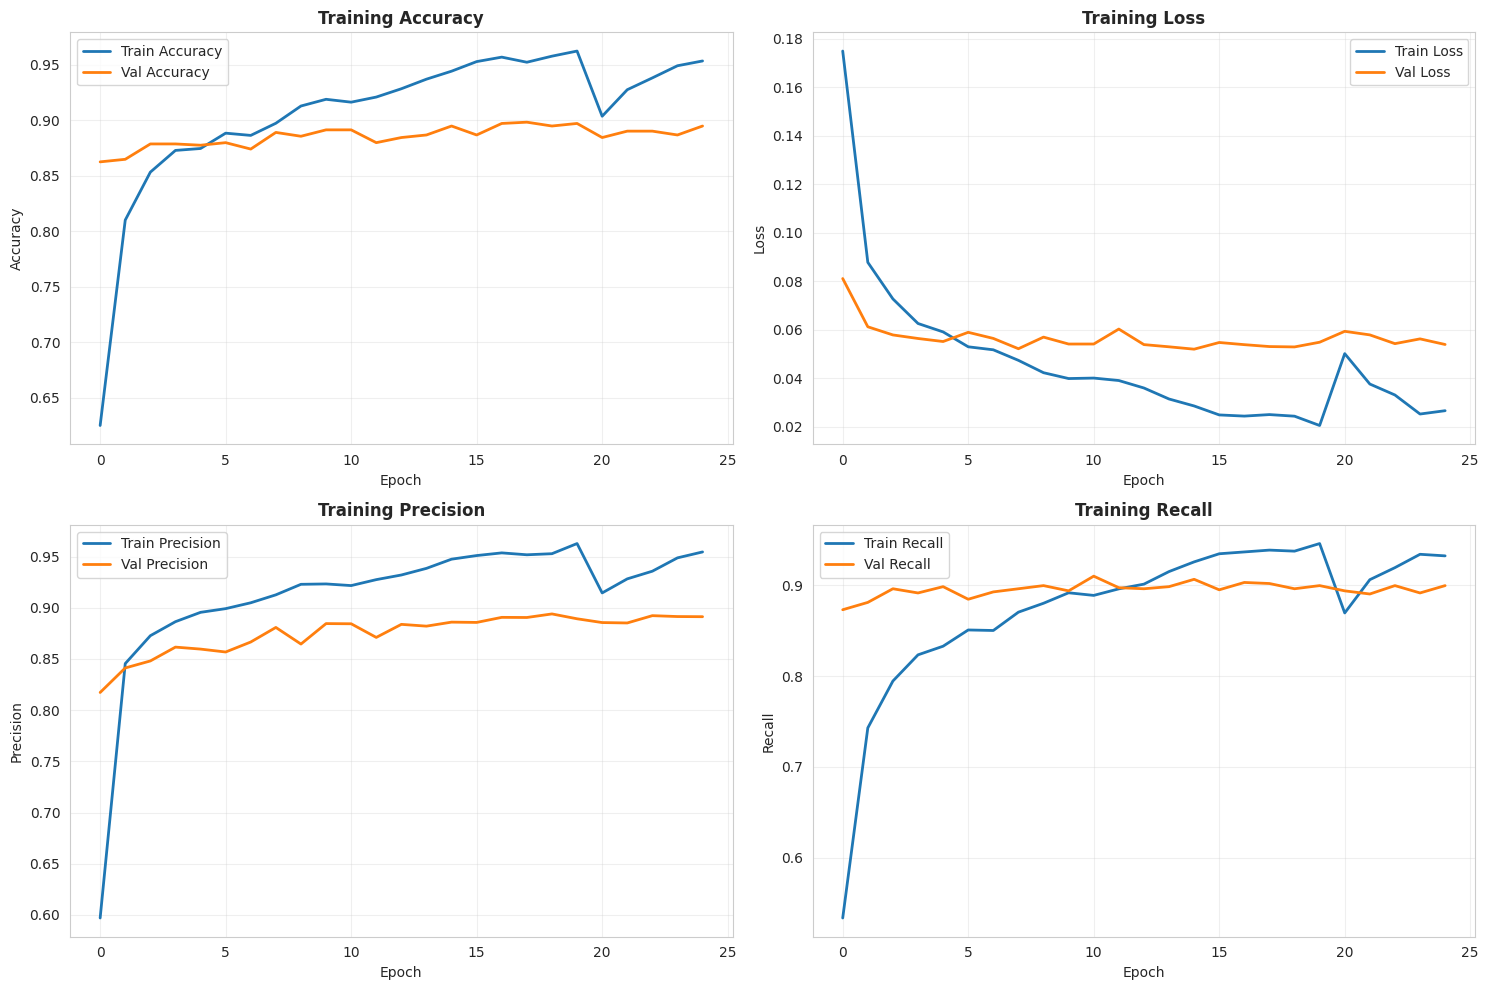

In [16]:
def plot_training_history(history):
    """Visualizes training metrics"""

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    axes[0, 0].plot(history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[0, 0].plot(history['val_accuracy'], label='Val Accuracy', linewidth=2)
    axes[0, 0].set_title('Training Accuracy', fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(history['loss'], label='Train Loss', linewidth=2)
    axes[0, 1].plot(history['val_loss'], label='Val Loss', linewidth=2)
    axes[0, 1].set_title('Training Loss', fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(history['precision'], label='Train Precision', linewidth=2)
    axes[1, 0].plot(history['val_precision'], label='Val Precision', linewidth=2)
    axes[1, 0].set_title('Training Precision', fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Precision')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    axes[1, 1].plot(history['recall'], label='Train Recall', linewidth=2)
    axes[1, 1].plot(history['val_recall'], label='Val Recall', linewidth=2)
    axes[1, 1].set_title('Training Recall', fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Recall')
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_history(history_combined)

## Validation Set Evaluation

In [17]:
# Saving model into a tf format to use in a production environment
model.export(MAIN_PATH + '/models/unique_model/unique_model_multilabel')

INFO:tensorflow:Assets written to: ./Part-1/models/unique_model/unique_model_multilabel/assets
Saved artifact at './Part-1/models/unique_model/unique_model_multilabel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_243')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  124775783314256: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  124775783316752: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  124775785568144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124775785567952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124775785566032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124775785569296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124775785569872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124775785568720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  

In [18]:
# Deleting memory to avoid kernel crashes and allocated resources not used
K.clear_session()
gc.collect()

#Loading the best model and evaluating on the validation set
model = keras.models.load_model(MAIN_PATH + '/models/unique_model/unique_model_multilabel.keras')

results = model.evaluate(validation_generator, verbose=1)

print(f"Loss: {results[0]:.4f}")
print(f"Accuracy: {results[1]:.4f}")
print(f"Precision: {results[2]:.4f}")
print(f"Recall: {results[3]:.4f}")

55/55 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - accuracy: 0.8984 - loss: 0.0531 - precision: 0.8905 - recall: 0.9018
Loss: 0.0531
Accuracy: 0.8984
Precision: 0.8905
Recall: 0.9018


## Confusion Matrix

55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step


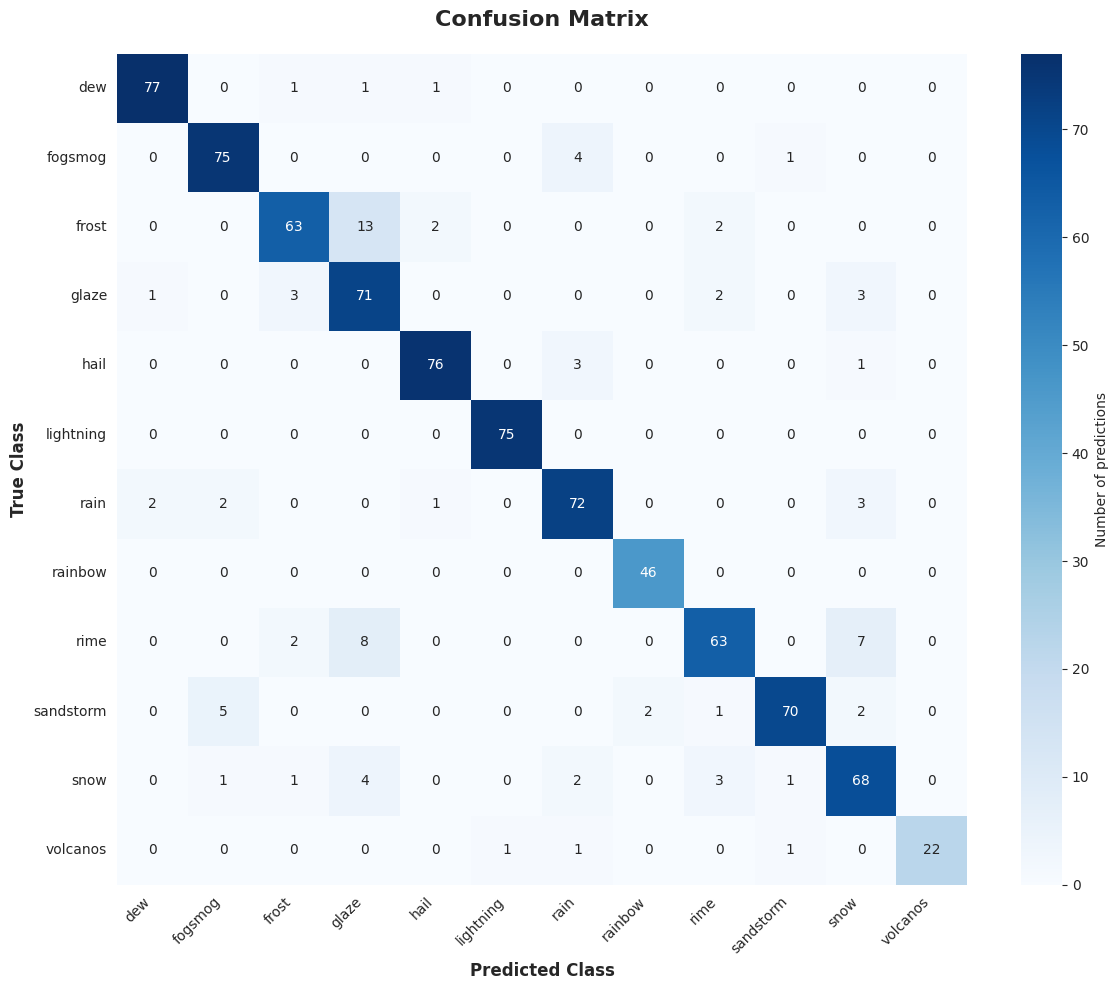

In [19]:
validation_generator.reset()
predictions = model.predict(validation_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_generator.classes
class_labels = list(validation_generator.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels,
            cbar_kws={'label': 'Number of predictions'})
plt.title('Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Classification Report


In [20]:
report = classification_report(true_classes, predicted_classes,
                               target_names=class_labels,
                               digits=4)
print(report)

report_dict = classification_report(true_classes, predicted_classes,
                                    target_names=class_labels,
                                    output_dict=True)

df_report = pd.DataFrame(report_dict).transpose()
df_report = df_report.round(4)
print(df_report)

              precision    recall  f1-score   support

         dew     0.9625    0.9625    0.9625        80
     fogsmog     0.9036    0.9375    0.9202        80
       frost     0.9000    0.7875    0.8400        80
       glaze     0.7320    0.8875    0.8023        80
        hail     0.9500    0.9500    0.9500        80
   lightning     0.9868    1.0000    0.9934        75
        rain     0.8780    0.9000    0.8889        80
     rainbow     0.9583    1.0000    0.9787        46
        rime     0.8873    0.7875    0.8344        80
   sandstorm     0.9589    0.8750    0.9150        80
        snow     0.8095    0.8500    0.8293        80
    volcanos     1.0000    0.8800    0.9362        25

    accuracy                         0.8984       866
   macro avg     0.9106    0.9015    0.9042       866
weighted avg     0.9026    0.8984    0.8988       866

              precision  recall  f1-score   support
dew              0.9625  0.9625    0.9625   80.0000
fogsmog          0.9036  0.93

## Feature Extraction and Visualization

In [21]:
def extract_features_robust(model, generator):
    """
    Robust version for feature extraction
    """
    base_model = None
    for layer in model.layers:
        if hasattr(layer, 'layers'):
            base_model = layer
            break

    if base_model is None:
        base_model = model.layers[0]

    feature_extractor = keras.Model(
        inputs=base_model.input,
        outputs=base_model.output
    )

    generator.reset()
    features = []
    labels = []

    steps = len(generator)

    print("Extracting features...")
    for i in range(steps):
        x_batch, y_batch = next(generator)
        features_batch = feature_extractor.predict(x_batch, verbose=0)

        if len(features_batch.shape) == 4:
            features_batch = np.mean(features_batch, axis=(1, 2))

        features.append(features_batch)
        labels.append(np.argmax(y_batch, axis=1))

    features = np.vstack(features)
    labels = np.hstack(labels)

    print(f"✓ Features extracted: {features.shape}")
    return features, labels

features, labels = extract_features_robust(model, validation_generator)

Extracting features...
✓ Features extracted: (866, 1280)


Applying t-SNE for dimensionality reduction...
Number of samples: 866
Using perplexity: 30


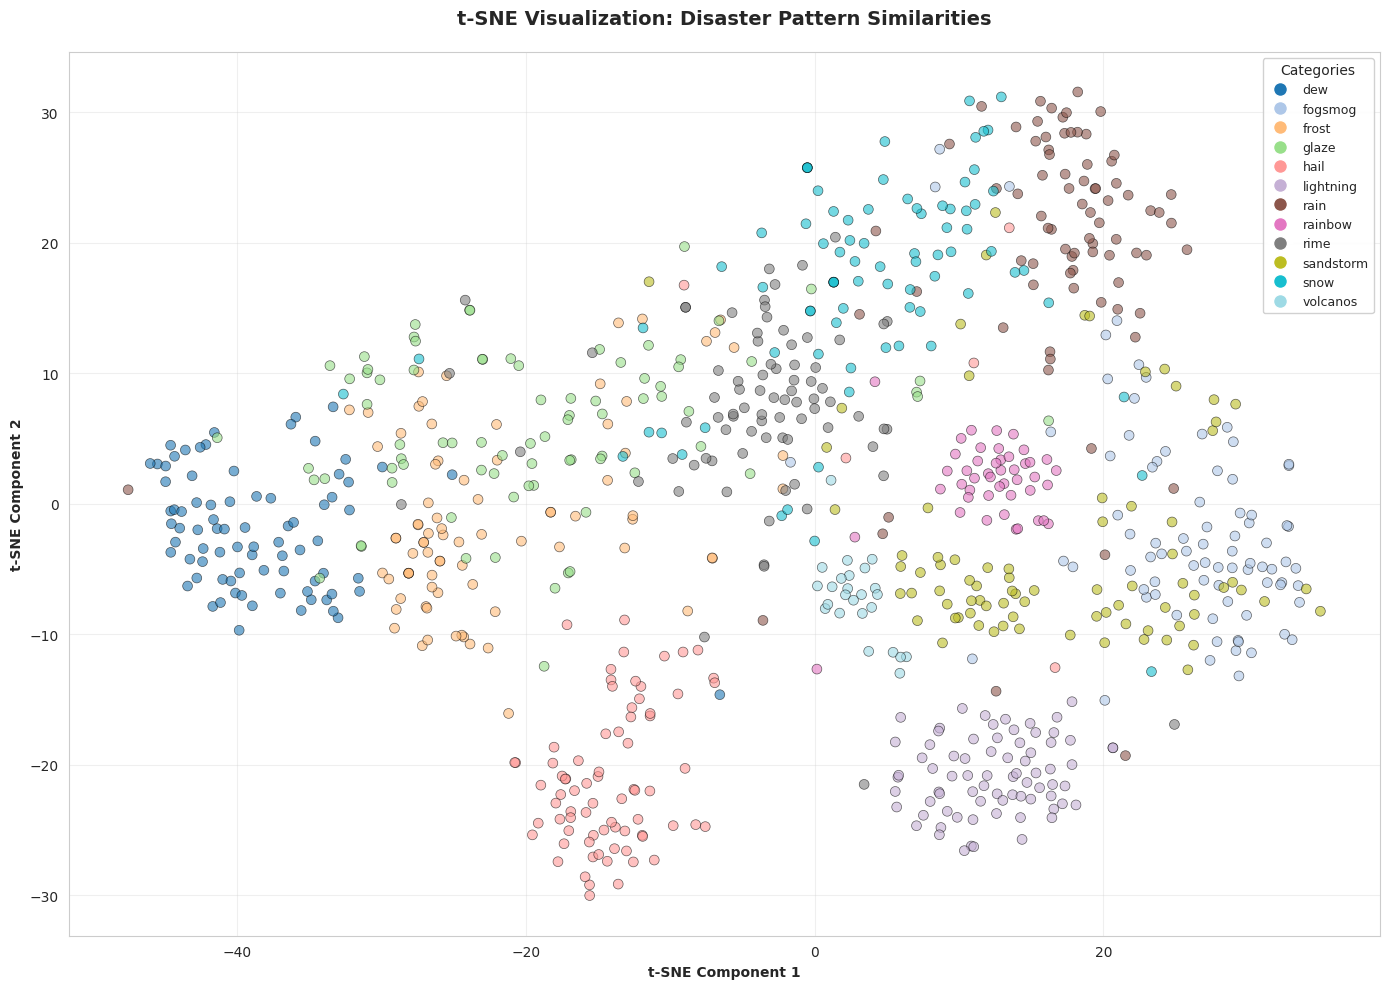


t-SNE INTERPRETATION
• Close points = similar visual patterns
• Well-separated clusters = model distinguishes classes well
• Mixed clusters = categories with similar characteristics


In [22]:
print("Applying t-SNE for dimensionality reduction...")
print(f"Number of samples: {features.shape[0]}")

n_samples = features.shape[0]
perplexity = min(30, n_samples - 1)

if n_samples < 50:
    perplexity = max(5, n_samples // 3)
elif n_samples < 100:
    perplexity = 10
elif n_samples < 200:
    perplexity = 15
else:
    perplexity = 30

print(f"Using perplexity: {perplexity}")

try:
    tsne = TSNE(n_components=2, random_state=CONFIG['SEED'],
                perplexity=perplexity, max_iter=1000)
    features_2d = tsne.fit_transform(features)

    plt.figure(figsize=(14, 10))
    scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1],
                         c=labels, cmap='tab20',
                         s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

    handles = [plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=scatter.cmap(scatter.norm(i)),
                          markersize=10, label=class_labels[i])
               for i in range(len(class_labels))]
    plt.legend(handles=handles, title='Categories',
              loc='best', framealpha=0.9, fontsize=9)

    plt.title('t-SNE Visualization: Disaster Pattern Similarities',
             fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('t-SNE Component 1', fontweight='bold')
    plt.ylabel('t-SNE Component 2', fontweight='bold')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 60)
    print("t-SNE INTERPRETATION")
    print("=" * 60)
    print("• Close points = similar visual patterns")
    print("• Well-separated clusters = model distinguishes classes well")
    print("• Mixed clusters = categories with similar characteristics")
    print("=" * 60)

except Exception as e:
    print(f"t-SNE error: {e}")
    print("Trying PCA as alternative...")

    pca = PCA(n_components=2, random_state=CONFIG['SEED'])
    features_2d = pca.fit_transform(features)

    plt.figure(figsize=(14, 10))
    scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1],
                         c=labels, cmap='tab20',
                         s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

    handles = [plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=scatter.cmap(scatter.norm(i)),
                          markersize=10, label=class_labels[i])
               for i in range(len(class_labels))]
    plt.legend(handles=handles, title='Categories',
              loc='best', framealpha=0.9, fontsize=9)

    plt.title('PCA Visualization: Disaster Pattern Similarities',
             fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Principal Component 1', fontweight='bold')
    plt.ylabel('Principal Component 2', fontweight='bold')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Variance explained by components: {pca.explained_variance_ratio_.sum():.2%}")
    print("PCA is a more stable alternative for visualization with few samples.")

## Average Distance Between Classes

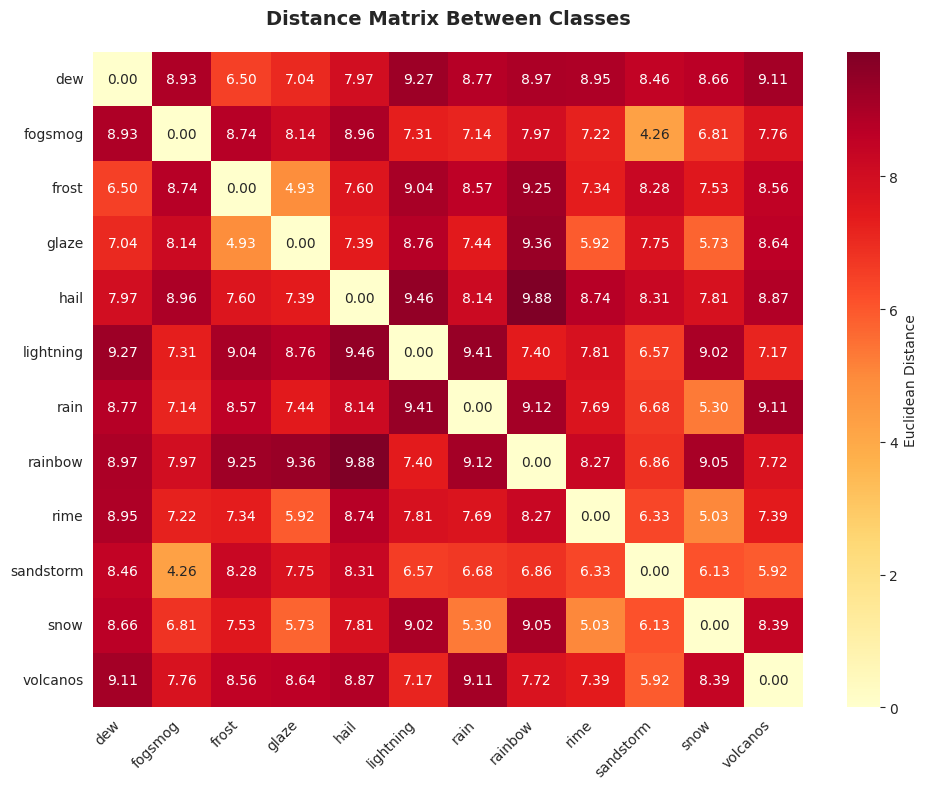


MOST SIMILAR CLASS PAIRS (smallest distance)
1. fogsmog ↔ sandstorm: 4.26
2. frost ↔ glaze: 4.93
3. rime ↔ snow: 5.03
4. rain ↔ snow: 5.30
5. glaze ↔ snow: 5.73

MOST DIFFERENT CLASS PAIRS (largest distance)
1. hail ↔ rainbow: 9.88
2. hail ↔ lightning: 9.46
3. lightning ↔ rain: 9.41
4. glaze ↔ rainbow: 9.36
5. dew ↔ lightning: 9.27


In [23]:
def analyze_class_distances(features, labels, class_labels):
    """
    Analyzes average distances between different classes
    """
    centroids = []
    for i in range(len(class_labels)):
        class_features = features[labels == i]
        if len(class_features) > 0:
                    centroid = np.mean(class_features, axis=0)
                    centroids.append(centroid)
        else:
            print(f"Warning: Class '{class_labels[i]}' has no data. It will be skipped.")
            # Using np.nan avoids creating fake centroids at the origin
            centroids.append(np.full(features.shape[1], np.nan))

    centroids = np.array(centroids)

    distance_matrix = cdist(centroids, centroids, metric='euclidean')

    plt.figure(figsize=(10, 8))
    sns.heatmap(distance_matrix, annot=True, fmt='.2f', cmap='YlOrRd',
                xticklabels=class_labels, yticklabels=class_labels,
                cbar_kws={'label': 'Euclidean Distance'})
    plt.title('Distance Matrix Between Classes',
             fontsize=14, fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print("\n" + "=" * 60)
    print("MOST SIMILAR CLASS PAIRS (smallest distance)")
    print("=" * 60)

    distances = []
    for i in range(len(class_labels)):
        for j in range(i + 1, len(class_labels)):
            distances.append((class_labels[i], class_labels[j], distance_matrix[i, j]))

    distances.sort(key=lambda x: x[2])

    for i, (class1, class2, dist) in enumerate(distances[:5], 1):
        print(f"{i}. {class1} ↔ {class2}: {dist:.2f}")

    print("\n" + "=" * 60)
    print("MOST DIFFERENT CLASS PAIRS (largest distance)")
    print("=" * 60)

    for i, (class1, class2, dist) in enumerate(distances[-5:][::-1], 1):
        print(f"{i}. {class1} ↔ {class2}: {dist:.2f}")

    print("=" * 60)

analyze_class_distances(features, labels, class_labels)

## Model Prediction Testing

In [24]:
def predict_image(model, img_path, class_labels, img_size=(224, 224)):
    """
    Predicts image class and shows probabilities
    """
    img = keras.preprocessing.image.load_img(img_path, target_size=img_size)
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class = class_labels[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.imshow(img)
    ax1.axis('off')
    ax1.set_title(f'Prediction: {predicted_class}\nConfidence: {confidence:.2%}',
                  fontsize=12, fontweight='bold')

    colors = ['green' if i == predicted_class_idx else 'steelblue'
              for i in range(len(class_labels))]
    ax2.barh(class_labels, predictions[0] * 100, color=colors, edgecolor='black')
    ax2.set_xlabel('Probability (%)', fontweight='bold')
    ax2.set_title('Probability Distribution', fontweight='bold')
    ax2.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    return predicted_class, confidence

In [25]:
def predict_random():
    random_category = np.random.choice(CATEGORIES)
    category_path = os.path.join(BASE_PATH, random_category)
    images = [f for f in os.listdir(category_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random_image = np.random.choice(images)
    test_image_path = os.path.join(category_path, random_image)

    predicted_class, confidence = predict_image(
        model,
        test_image_path,
        class_labels,
        CONFIG['IMG_SIZE']
    )
    
def predict_by_category(categoria):
    if categoria not in CATEGORIES:
        print(f"Category '{categoria}' not found in dataset.")
        return

    category_path = os.path.join(BASE_PATH, categoria)
    images = [f for f in os.listdir(category_path)
              if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random_image = np.random.choice(images)
    test_image_path = os.path.join(category_path, random_image)

    predicted_class, confidence = predict_image(
        model,
        test_image_path,
        class_labels,
        CONFIG['IMG_SIZE']
    )

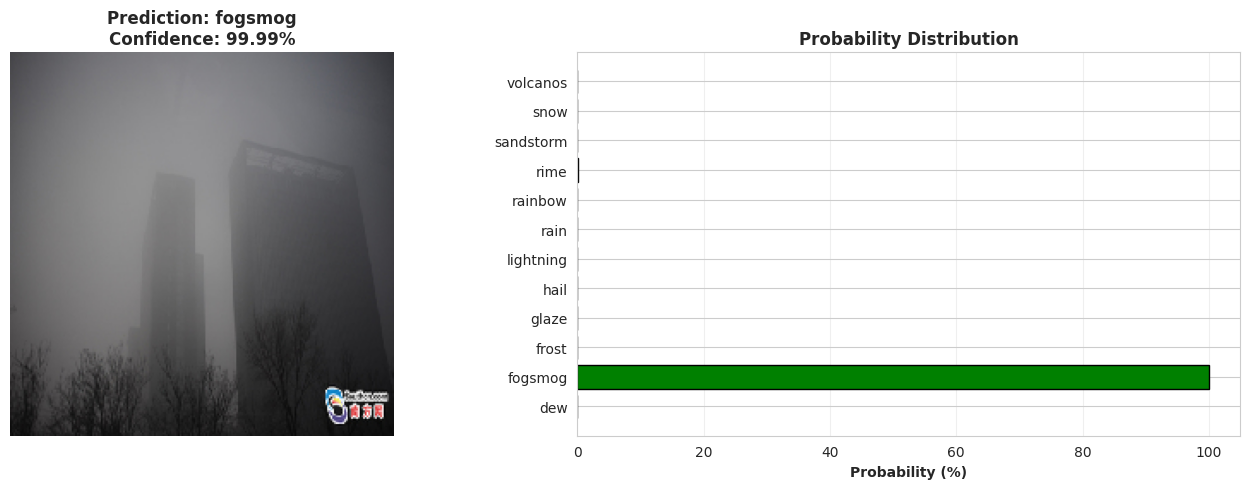

In [26]:
#Example prediction
predict_random()

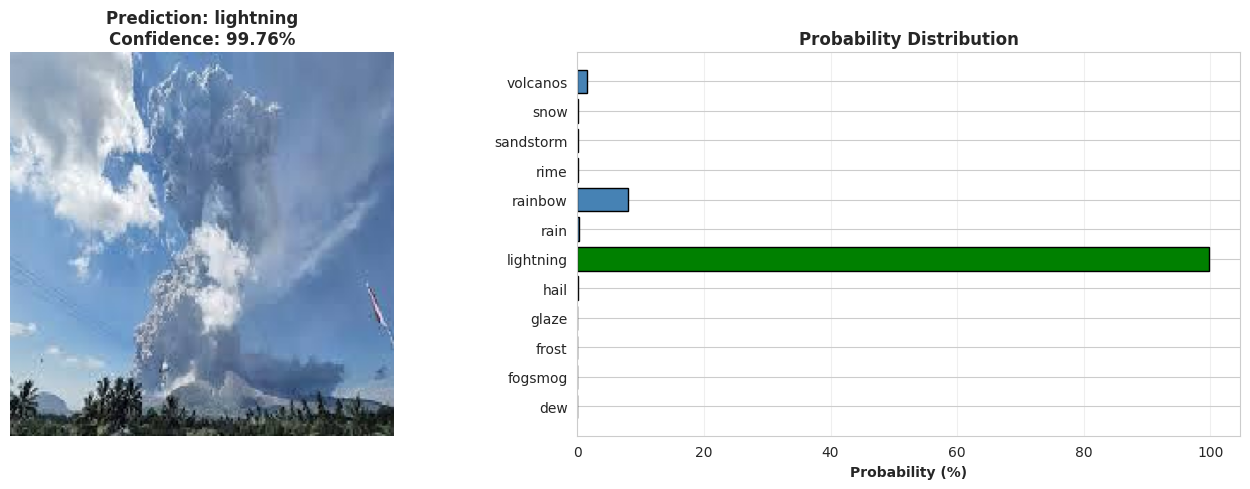

In [27]:
#Prediction example 2
predict_random()

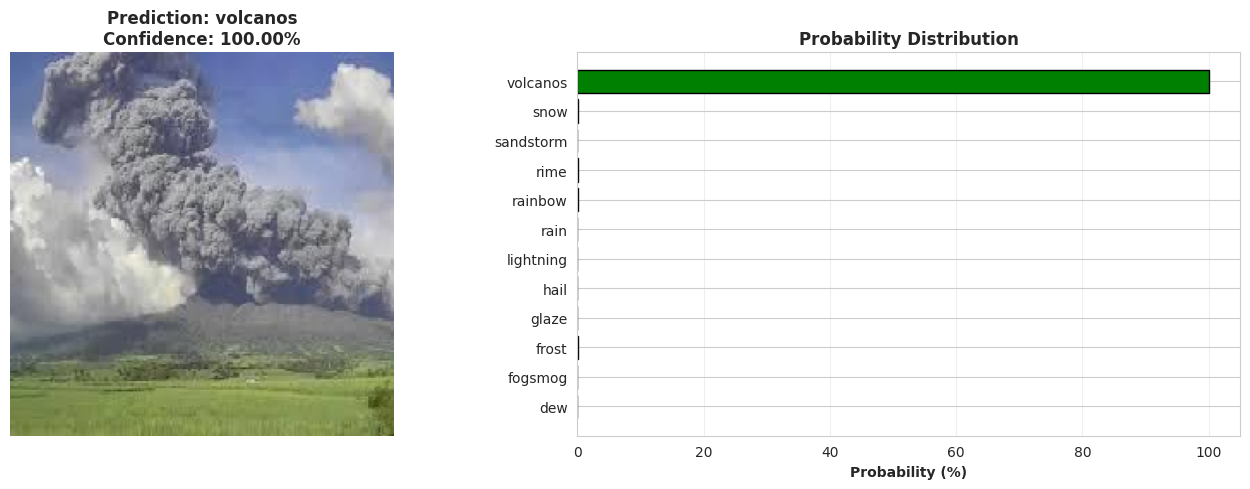

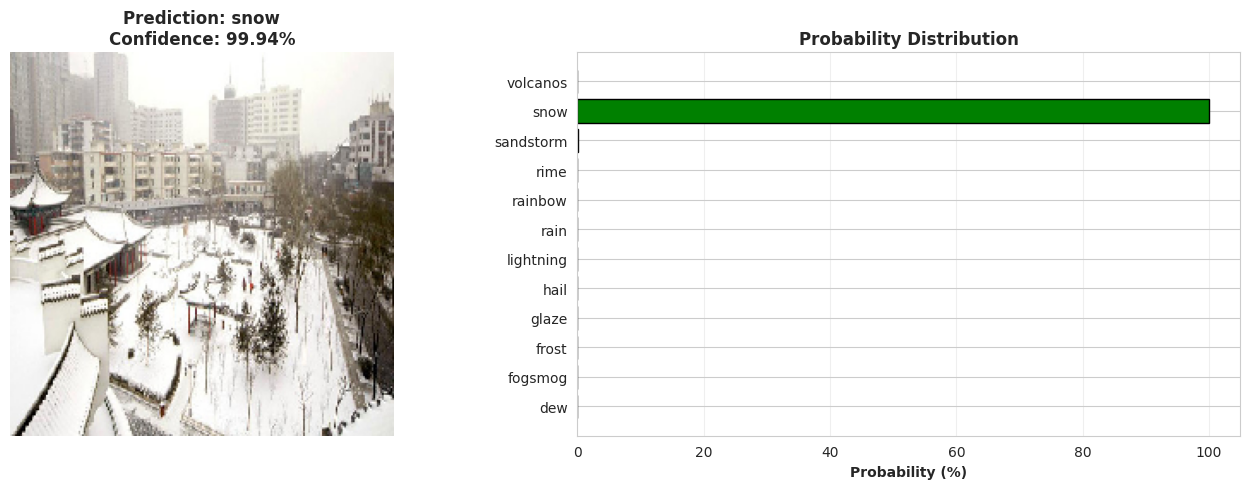

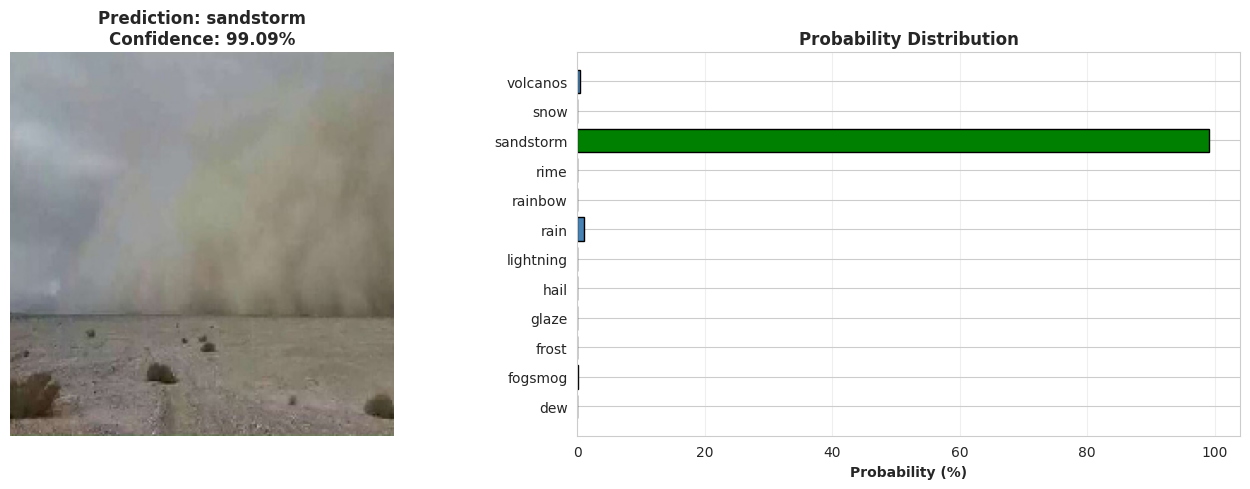

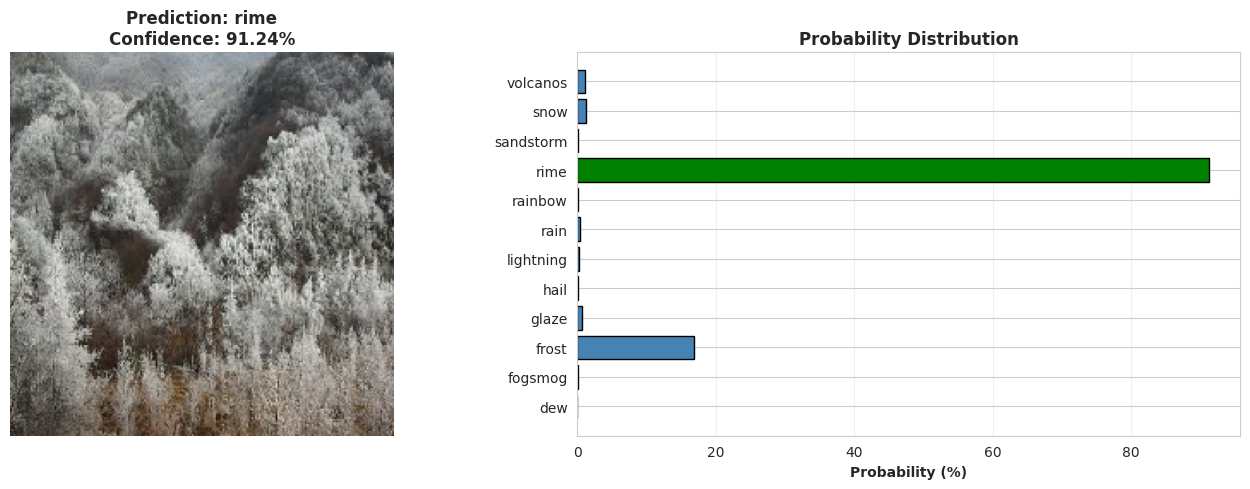

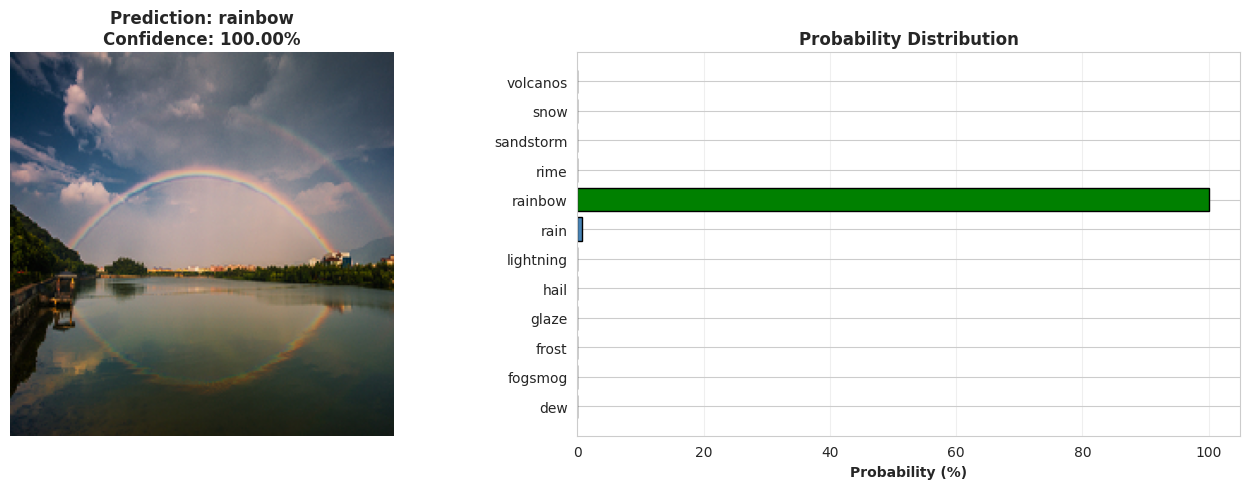

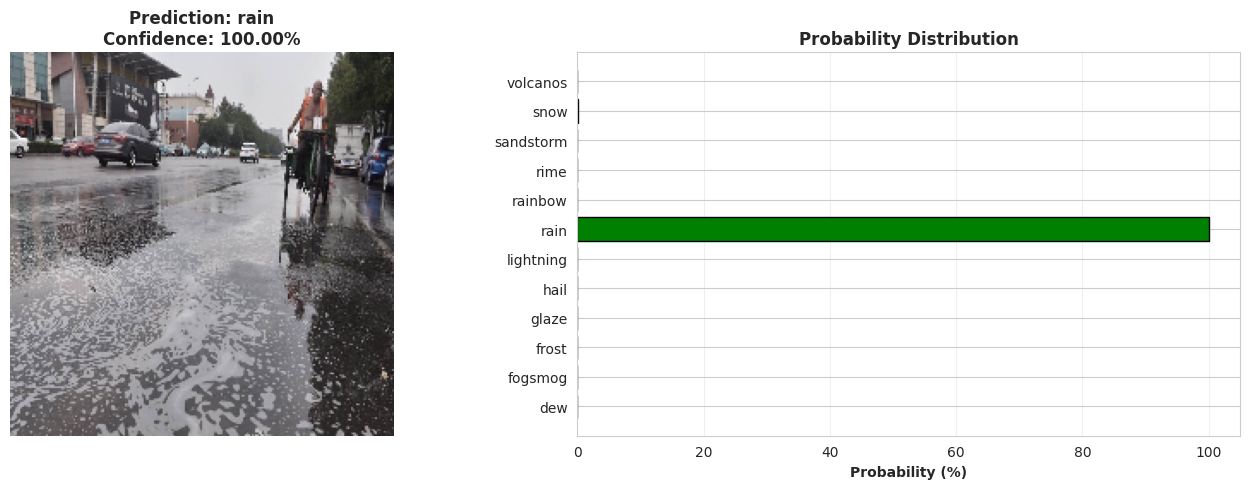

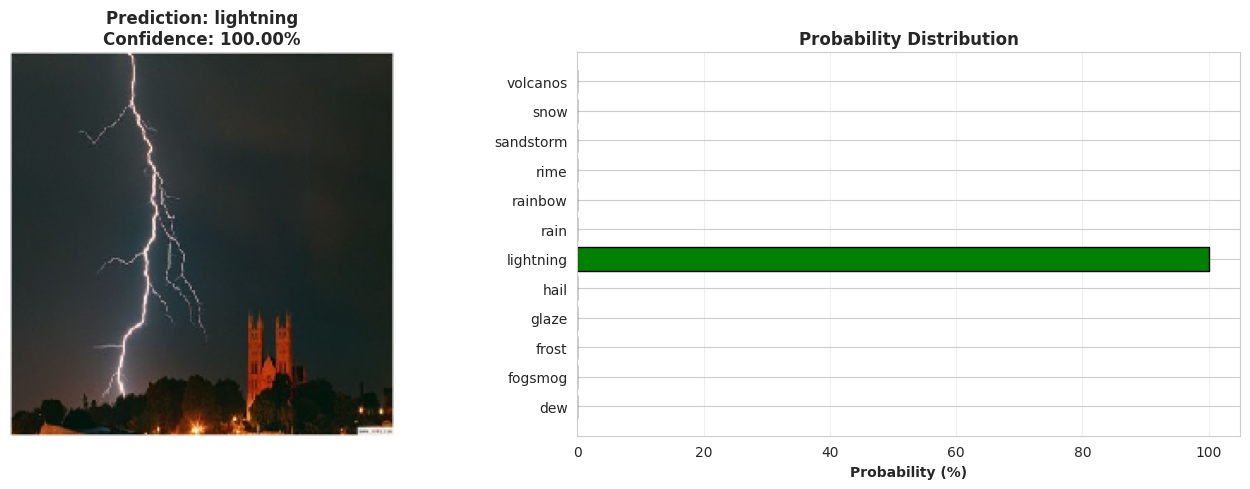

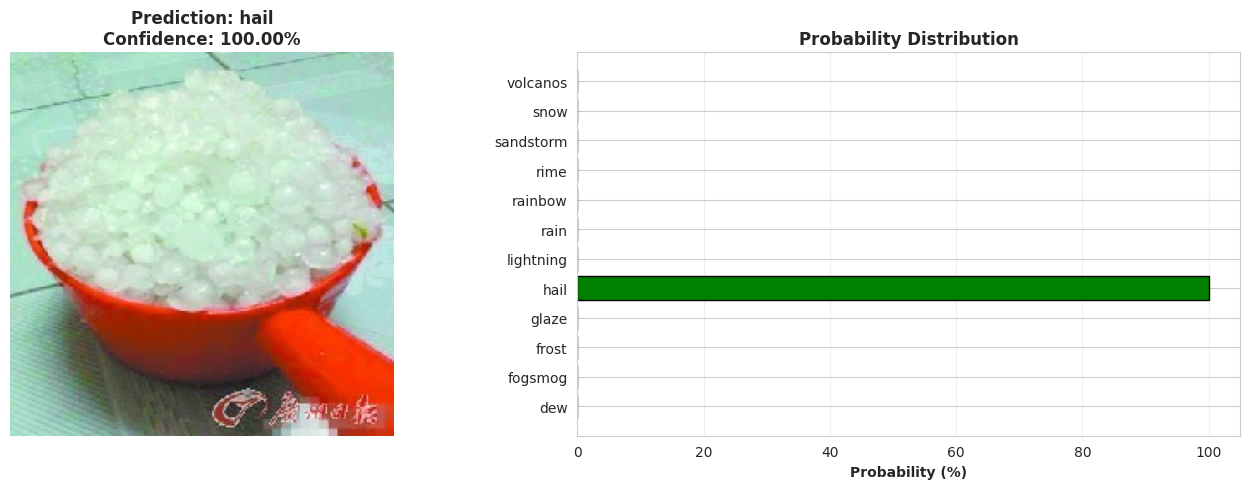

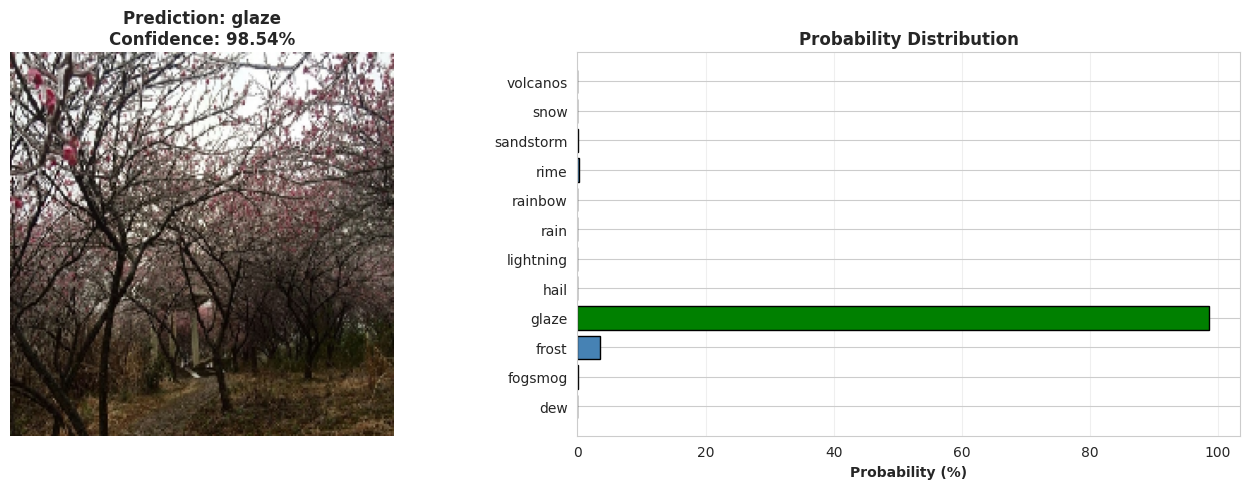

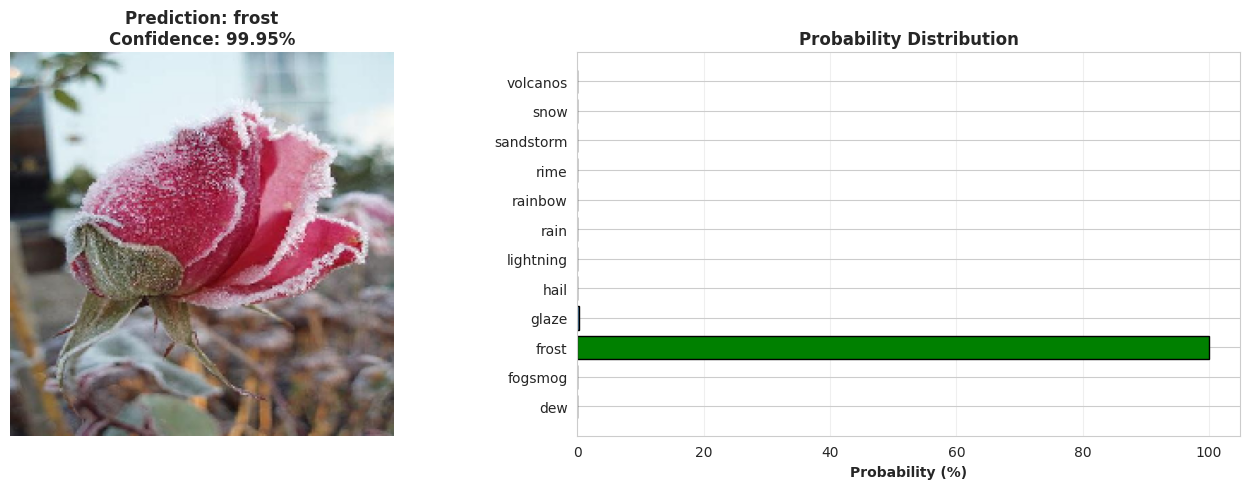

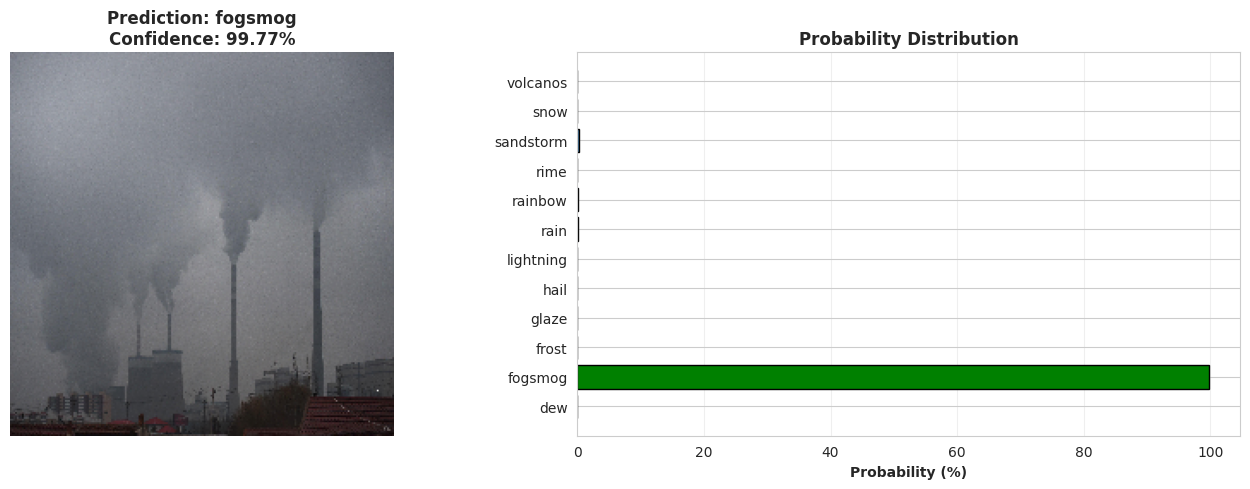

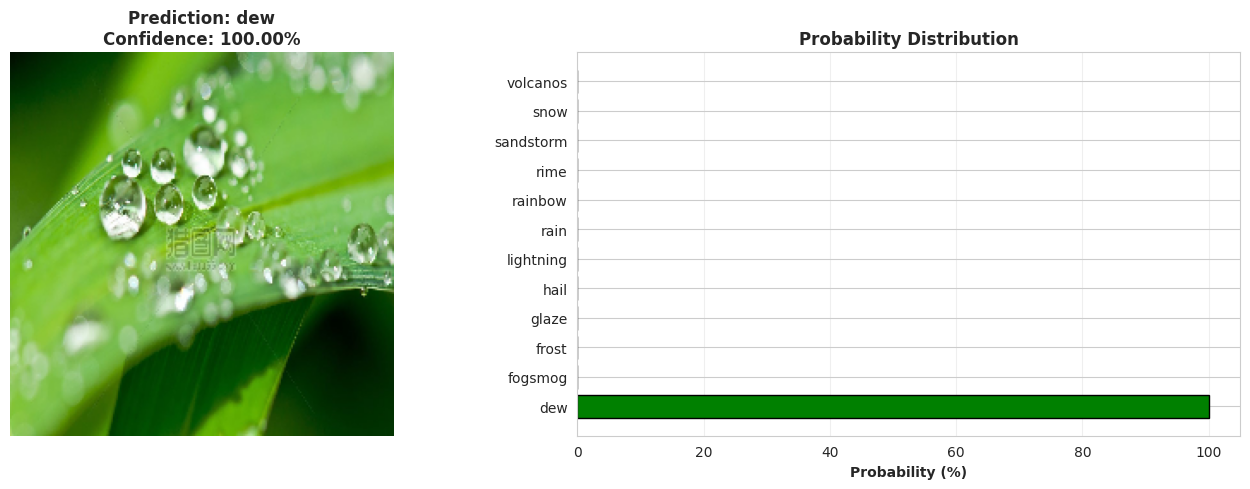

In [28]:
#Prediction example 3
predict_by_category('volcanos')
predict_by_category('snow')
predict_by_category('sandstorm')
predict_by_category('rime')
predict_by_category('rainbow')
predict_by_category('rain')
predict_by_category('lightning')
predict_by_category('hail')
predict_by_category('glaze')
predict_by_category('frost')
predict_by_category('fogsmog')
predict_by_category('dew')
    

In [29]:
def predict_external_image(model, img_path):
    """
    Predicts class of an external image
    """
    if not os.path.exists(img_path):
        print(f"✗ Image does not exist: {img_path}")
        return

    predicted_class, confidence = predict_image(
        model,
        img_path,
        class_labels,
        CONFIG['IMG_SIZE']
    )


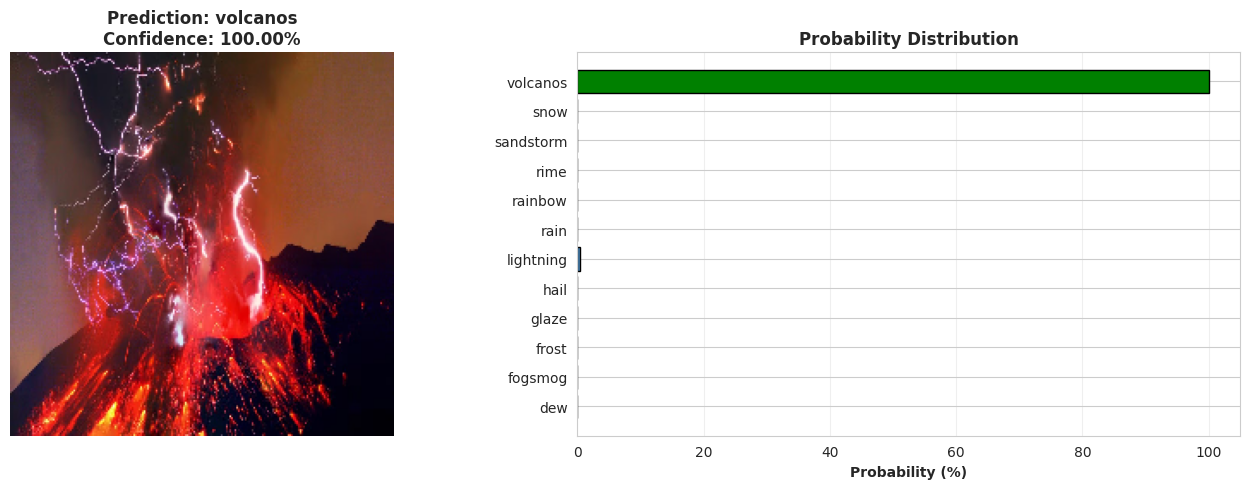

In [30]:
external_image_path = MAIN_PATH+'/predict/volcano_lightning.jpeg'  
predict_external_image(model, external_image_path)

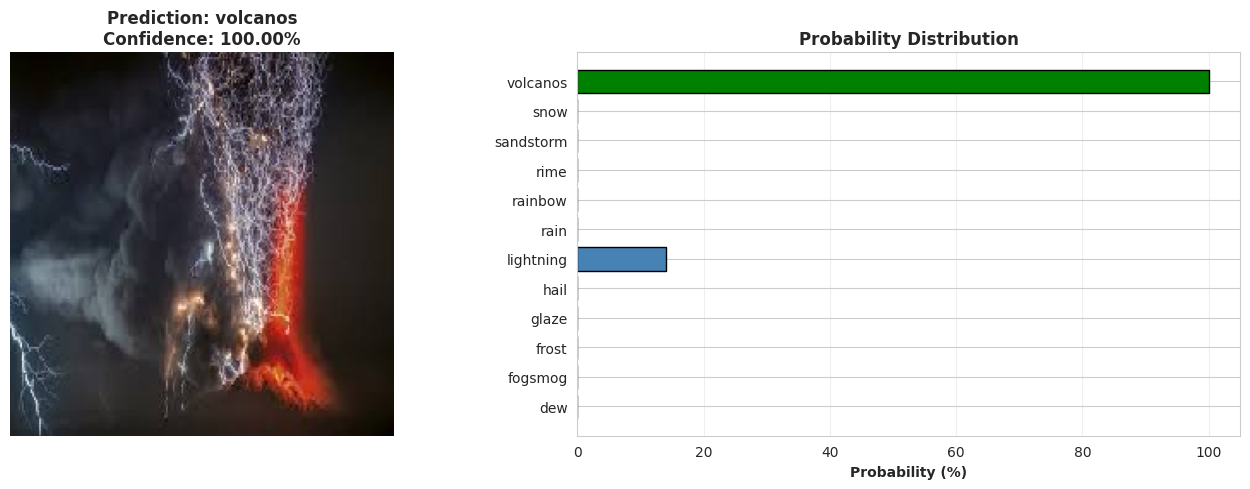

In [31]:
external_image_path = MAIN_PATH+'/predict/volcano_lightning_2.jpg'  
predict_external_image(model, external_image_path)

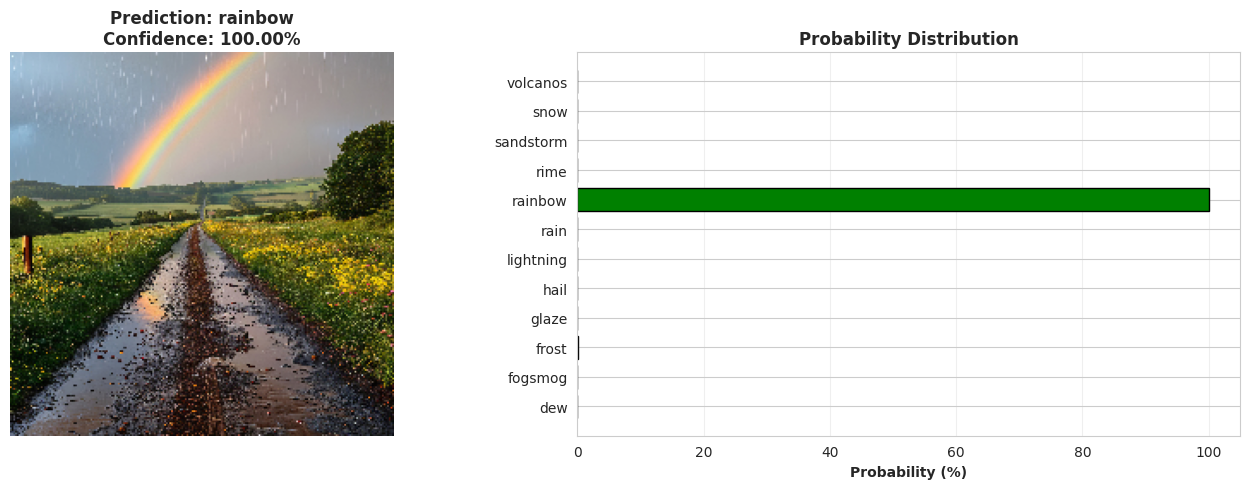

In [32]:
external_image_path = MAIN_PATH+'/predict/rainbow-rain.jpg'  
predict_external_image(model, external_image_path)

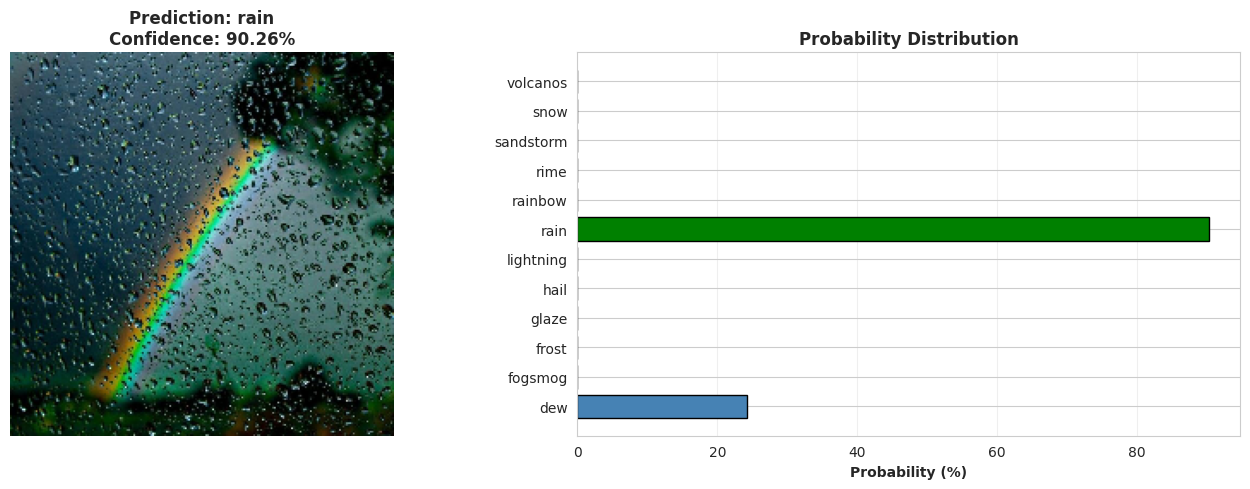

In [33]:
external_image_path = MAIN_PATH+'/predict/rainbow-rain-2.jpg'  
predict_external_image(model, external_image_path)

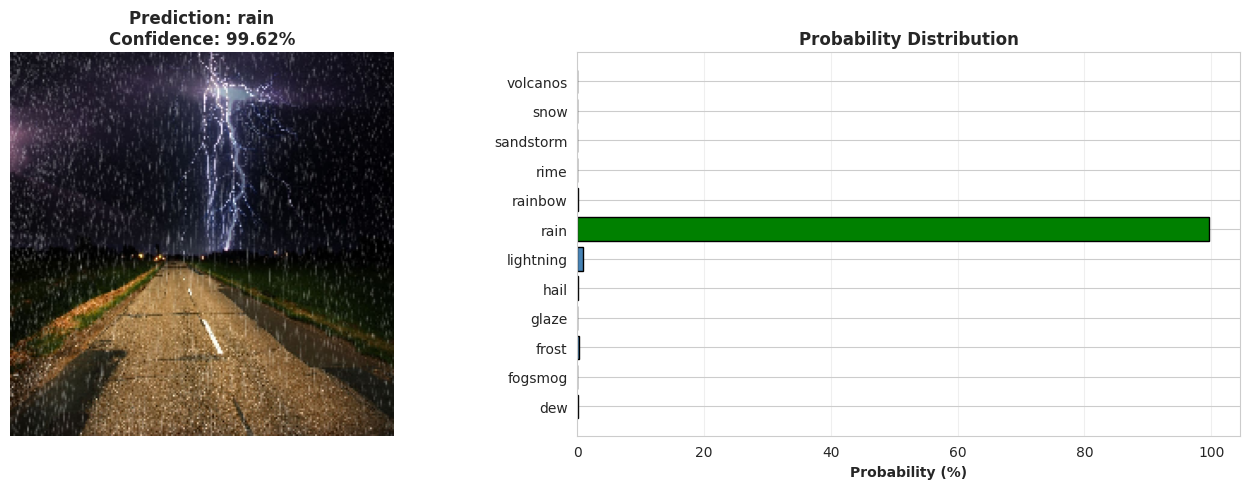

In [34]:
external_image_path = MAIN_PATH+'/predict/rain-lightning.jpg' 
predict_external_image(model, external_image_path)

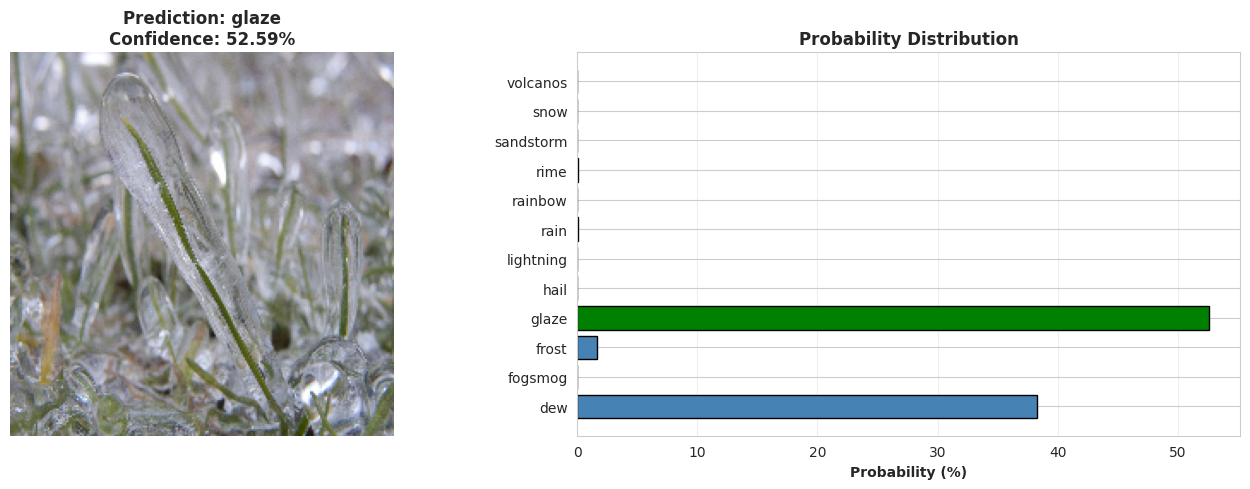

In [35]:
external_image_path = MAIN_PATH+'/predict/glaze.jpg' 
predict_external_image(model, external_image_path)